# Zimbabwe Healthcare Accessibility Explorer
## Notebook 4 — Population Accessibility Analysis
**Author: Tinashe Clifford Makandise**

### Purpose
Calculate nearest mapped-facility distances from populated grid-cell centres, weight the results by estimated population, and summarise by district. Search all prepared in-country facilities, including those in neighbouring districts.

Run Notebooks 1–3 first. Save here in `notebooks/`. This stage adds **SciPy** for an efficient spatial index. If it is not installed, run `%pip install scipy` in a separate notebook cell, restart the kernel if requested, and run all cells. Other libraries are already in `requirements-dev.txt`. No data downloads are required.

### Interpretation
We measure shortest surface distance on the WGS84 ellipsoid, commonly described here as straight-line geographic distance. These are not road distances, travel times, capacity estimates or official healthcare access classifications. Historical public-sector/not-for-profit facility records and 2020 modelled population form a mixed-period exploratory analysis. Missing facilities and 35 source records without usable coordinates limit completeness. Facilities outside Zimbabwe are not in the search, potentially overstating distance near international borders.

In [1]:
from pathlib import Path
import json, hashlib, platform
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
from pyproj import Geod, Transformer
try:
    import scipy
    from scipy.spatial import cKDTree
except ImportError as exc:
    raise ImportError("Install SciPy in this notebook's environment with %pip install scipy, then rerun.") from exc

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROCESSED, REPORTS = ROOT / "data/raw", ROOT / "data/processed", ROOT / "reports"
MAPS, TABLES = ROOT / "outputs/maps", ROOT / "outputs/tables"
for folder in [MAPS, TABLES, REPORTS]:
    folder.mkdir(parents=True, exist_ok=True)
preparation = json.loads((REPORTS / "02_preparation_report.json").read_text(encoding="utf-8"))
input_names = ["facilities_prepared.geojson", "districts_prepared.geojson", "population_cells_prepared.csv"]
input_hashes = {}
for name in input_names:
    path = PROCESSED / name
    if not path.is_file():
        raise FileNotFoundError(f"Run Notebook 2 first: missing {path}")
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    assert digest == preparation["output_sha256"][name], f"Prepared file changed: {name}"
    input_hashes[name] = digest
facilities = gpd.read_file(PROCESSED / "facilities_prepared.geojson").sort_values("facility_id").reset_index(drop=True)
districts = gpd.read_file(PROCESSED / "districts_prepared.geojson")
population = pd.read_csv(PROCESSED / "population_cells_prepared.csv", dtype={"adm2_pcode": "string", "adm1_pcode": "string"})
assert len(facilities) > 0 and facilities.facility_id.is_unique and population.cell_id.is_unique
assert (population.population > 0).all() and np.isfinite(population.population).all()
assert np.isfinite(facilities[["latitude", "longitude"]]).all().all()
assert np.isfinite(population[["latitude", "longitude"]]).all().all()
assert districts.adm2_pcode.is_unique
np.testing.assert_allclose(population.population.sum(), preparation["population_audit"]["inside_country_population"], rtol=1e-10)
print(f"Loaded {len(population):,} population centres and {len(facilities):,} mapped facilities.")
print("Distance method: WGS84 ellipsoidal geodesic; no road network or travel-time conversion.")

Loaded 479,031 population centres and 1,201 mapped facilities.
Distance method: WGS84 ellipsoidal geodesic; no road network or travel-time conversion.


### 1. Find the nearest facility efficiently and accurately
An ordinary longitude/latitude nearest-neighbour search would treat degrees as a flat distance. Instead:

1. Transform coordinates at zero ellipsoidal height into Earth-centred Cartesian coordinates (metres).
2. Find the closest facility by 3D chord distance and compute its ellipsoidal geodesic distance, giving an upper bound on the true nearest distance.
3. Query all facilities whose chord distance is within that upper bound, then compute their actual geodesic distances.
4. Choose the smallest geodesic distance; an exact distance tie is resolved by sorted facility ID.

A straight 3D chord cannot exceed the length of a surface path connecting its endpoints. Therefore any closer facility must be inside this query radius. This method refines all potential winners, not just an arbitrary fixed number of neighbours. A one-micrometre radius margin accommodates floating-point rounding. All coordinates are assumed on the reference ellipsoid, without terrain or altitude effects.

In [2]:
geod = Geod(ellps="WGS84")
to_ecef = Transformer.from_crs("EPSG:4979", "EPSG:4978", always_xy=True)

def ecef(longitude, latitude):
    longitude, latitude = np.asarray(longitude, dtype=float), np.asarray(latitude, dtype=float)
    return np.column_stack(to_ecef.transform(longitude, latitude, np.zeros_like(longitude)))

facility_lon = facilities.longitude.to_numpy(dtype=float)
facility_lat = facilities.latitude.to_numpy(dtype=float)
facility_xyz = ecef(facility_lon, facility_lat)
tree = cKDTree(facility_xyz)

def nearest_facility(longitude, latitude, batch_size=20000):
    longitude, latitude = np.asarray(longitude, dtype=float), np.asarray(latitude, dtype=float)
    best_index = np.empty(len(longitude), dtype=int)
    best_distance_m = np.empty(len(longitude), dtype=float)
    candidate_counts = np.empty(len(longitude), dtype=int)
    for start in range(0, len(longitude), batch_size):
        stop = min(start + batch_size, len(longitude))
        lon, lat = longitude[start:stop], latitude[start:stop]
        xyz = ecef(lon, lat)
        _, first = tree.query(xyz, k=1)
        _, _, upper = geod.inv(lon, lat, facility_lon[first], facility_lat[first])
        neighbours = tree.query_ball_point(xyz, np.asarray(upper) + 1e-6)
        lengths = np.fromiter((len(items) for items in neighbours), dtype=int, count=len(lon))
        assert (lengths > 0).all()
        point_ids = np.repeat(np.arange(len(lon)), lengths)
        facility_ids = np.concatenate(neighbours).astype(int)
        _, _, distances = geod.inv(lon[point_ids], lat[point_ids], facility_lon[facility_ids], facility_lat[facility_ids])
        distances = np.asarray(distances)
        order = np.lexsort((facility_ids, distances, point_ids))
        sorted_points = point_ids[order]
        first_in_group = np.r_[True, sorted_points[1:] != sorted_points[:-1]]
        winners = order[first_in_group]
        assert np.array_equal(point_ids[winners], np.arange(len(lon)))
        best_index[start:stop] = facility_ids[winners]
        best_distance_m[start:stop] = distances[winners]
        candidate_counts[start:stop] = lengths
    return best_index, best_distance_m / 1000, candidate_counts

nearest_index, distance_km, candidate_counts = nearest_facility(population.longitude, population.latitude)
assert np.isfinite(distance_km).all() and (distance_km >= 0).all()
access = population.copy()
access["nearest_facility_id"] = facilities.facility_id.to_numpy()[nearest_index]
access["nearest_facility_name"] = facilities.facility_name.to_numpy()[nearest_index]
access["nearest_facility_type"] = facilities.facility_type.to_numpy()[nearest_index]
access["nearest_facility_district"] = facilities.adm2_pcode.to_numpy()[nearest_index]
access["distance_km"] = distance_km
access["nearest_in_other_district"] = access.adm2_pcode.notna() & access.nearest_facility_district.notna() & access.adm2_pcode.ne(access.nearest_facility_district)
print("Distances calculated for every prepared population centre.")
print("Candidate facilities refined per centre: mean", round(float(candidate_counts.mean()), 3), "maximum", int(candidate_counts.max()))
print("Minimum / maximum distance (km):", round(float(distance_km.min()), 4), round(float(distance_km.max()), 3))

Distances calculated for every prepared population centre.
Candidate facilities refined per centre: mean 1.0 maximum 2
Minimum / maximum distance (km): 0.0126 109.066


### 2. Verify selected results against all facilities
Use a seeded sample of 40 population centres and compare with exhaustive geodesic distances to every facility. Also check a co-located point gives approximately zero distance. These are numerical checks; they do not verify the real-world accuracy or operational status of source locations. Broader sensitivity and export validation follow in Notebook 5.

In [3]:
rng = np.random.default_rng(42)
check_indices = rng.choice(len(access), size=min(40, len(access)), replace=False)
validation_rows = []
for row_index in check_indices:
    lon, lat = float(access.longitude.iloc[row_index]), float(access.latitude.iloc[row_index])
    _, _, exhaustive_m = geod.inv(np.full(len(facilities), lon), np.full(len(facilities), lat), facility_lon, facility_lat)
    exhaustive_m = np.asarray(exhaustive_m)
    expected_index = int(np.argmin(exhaustive_m))
    actual_m = float(access.distance_km.iloc[row_index] * 1000)
    error = abs(actual_m - exhaustive_m[expected_index])
    assert error < 1e-5
    assert access.nearest_facility_id.iloc[row_index] == facilities.facility_id.iloc[expected_index]
    validation_rows.append({"cell_id": int(access.cell_id.iloc[row_index]), "absolute_distance_error_m": float(error), "nearest_id_matches": True})
_, zero_distance, _ = nearest_facility(facility_lon[:1], facility_lat[:1])
assert zero_distance[0] < 1e-8
pd.DataFrame(validation_rows).to_csv(TABLES / "04_nearest_search_numerical_checks.csv", index=False)
print(f"{len(validation_rows)} exhaustive comparisons passed; co-located zero-distance check passed.")

40 exhaustive comparisons passed; co-located zero-distance check passed.


### 3. Define illustrative thresholds and population weighting
Use thresholds of 5, 10 and 20 km for exploration, not official service standards. “Beyond” means strictly greater than the threshold; a cell exactly at 5 km belongs in the first band.

The mean uses population weights, not an unweighted mean of cell distances. Weighted quantiles are defined here as the first sorted distance at which cumulative population reaches the requested share (an inverse empirical CDF, without interpolation).

The denominator is the population assigned to in-country cell centres in Notebook 2. Population excluded by the national-centre rule remains recorded separately in the preparation report.

In [4]:
THRESHOLDS_KM = [5, 10, 20]
BAND_LABELS = ["0–5 km", ">5–10 km", ">10–20 km", ">20 km"]
access["distance_band"] = pd.cut(access.distance_km, bins=[-np.inf, 5, 10, 20, np.inf], labels=BAND_LABELS, right=True)
assert access.distance_band.notna().all()

def weighted_quantile(values, weights, quantile):
    order = np.argsort(values, kind="stable")
    sorted_values, sorted_weights = np.asarray(values)[order], np.asarray(weights)[order]
    cutoff = quantile * sorted_weights.sum()
    position = min(int(np.searchsorted(np.cumsum(sorted_weights), cutoff, side="left")), len(sorted_values) - 1)
    return float(sorted_values[position])

total_population = float(access.population.sum())
national = {"population_denominator": total_population, "population_cells": len(access), "mapped_facilities": len(facilities),
            "weighted_mean_distance_km": float(np.average(access.distance_km, weights=access.population)),
            "weighted_median_distance_km": weighted_quantile(access.distance_km, access.population, .5),
            "weighted_p90_distance_km": weighted_quantile(access.distance_km, access.population, .9),
            "maximum_cell_centre_distance_km": float(access.distance_km.max()),
            "nearest_other_district_population_percent": float(access.loc[access.nearest_in_other_district, "population"].sum() / total_population * 100)}
threshold_rows = []
for threshold in THRESHOLDS_KM:
    beyond = float(access.loc[access.distance_km > threshold, "population"].sum())
    national[f"population_beyond_{threshold}km"] = beyond
    national[f"percent_beyond_{threshold}km"] = beyond / total_population * 100
    threshold_rows.append({"threshold_km": threshold, "population_beyond": beyond,
                           "percent_beyond": beyond / total_population * 100,
                           "percent_within": (total_population - beyond) / total_population * 100})
threshold_summary = pd.DataFrame(threshold_rows)
band_population = access.groupby("distance_band", observed=False).population.sum().reindex(BAND_LABELS)
np.testing.assert_allclose(band_population.sum(), total_population, rtol=1e-10)
assert np.all(np.diff(threshold_summary.percent_beyond) <= 0)
print(json.dumps(national, indent=2))
print(threshold_summary.round(3).to_string(index=False))

{
  "population_denominator": 14851844.135005971,
  "population_cells": 479031,
  "mapped_facilities": 1201,
  "weighted_mean_distance_km": 6.425183259124973,
  "weighted_median_distance_km": 4.936762167810263,
  "weighted_p90_distance_km": 12.872425371207287,
  "maximum_cell_centre_distance_km": 109.06550552270043,
  "nearest_other_district_population_percent": 16.311938222548946,
  "population_beyond_5km": 7351043.3251219075,
  "percent_beyond_5km": 49.49582865467469,
  "population_beyond_10km": 2726223.5291820206,
  "percent_beyond_10km": 18.35612806329067,
  "population_beyond_20km": 430946.9898651019,
  "percent_beyond_20km": 2.9016395940309847
}
 threshold_km  population_beyond  percent_beyond  percent_within
            5        7351043.325          49.496          50.504
           10        2726223.529          18.356          81.644
           20         430946.990           2.902          97.098


### 4. Summarise by district without restricting facility choice
District membership determines where population indicators are reported, not which facilities may be reached. Calculate mean distance using population weights, plus population shares beyond each threshold. Keep all district polygons; any zero-population unit has undefined distance indicators rather than a misleading zero.

Country totals include all in-country population centres. If any centres lack district codes, show their population separately and reconcile assigned district totals to the assigned population—not automatically to the national total.

In [5]:
access["population_times_distance"] = access.population * access.distance_km
assigned = access.adm2_pcode.notna()
grouped = access.loc[assigned].groupby("adm2_pcode")
base = grouped.agg(population_estimate=("population", "sum"), population_cells=("cell_id", "size"),
                   distance_weighted_sum=("population_times_distance", "sum"))
base["weighted_mean_distance_km"] = base.distance_weighted_sum / base.population_estimate
for threshold in THRESHOLDS_KM:
    beyond = access.loc[assigned & access.distance_km.gt(threshold)].groupby("adm2_pcode").population.sum()
    base[f"population_beyond_{threshold}km"] = beyond.reindex(base.index, fill_value=0)
    base[f"percent_beyond_{threshold}km"] = base[f"population_beyond_{threshold}km"] / base.population_estimate * 100
quantiles = []
for code_value, frame in grouped:
    quantiles.append({"adm2_pcode": code_value,
                      "weighted_median_distance_km": weighted_quantile(frame.distance_km, frame.population, .5),
                      "weighted_p90_distance_km": weighted_quantile(frame.distance_km, frame.population, .9)})
base = base.join(pd.DataFrame(quantiles).set_index("adm2_pcode"))
district_access = districts.merge(base.drop(columns="distance_weighted_sum"), left_on="adm2_pcode", right_index=True, how="left", validate="one_to_one")
district_access["population_estimate"] = district_access.population_estimate.fillna(0)
district_access["population_cells"] = district_access.population_cells.fillna(0).astype(int)
district_access["district_label"] = district_access.adm2_name + " (" + district_access.adm2_pcode + ")"
np.testing.assert_allclose(district_access.population_estimate.sum(), access.loc[assigned, "population"].sum(), rtol=1e-10)
for threshold in THRESHOLDS_KM:
    np.testing.assert_allclose(district_access[f"population_beyond_{threshold}km"].sum(), access.loc[assigned & access.distance_km.gt(threshold), "population"].sum(), rtol=1e-10)
    assert district_access.loc[district_access.population_estimate.gt(0), f"percent_beyond_{threshold}km"].between(0, 100 + 1e-8).all()
print("Population without a district code:", float(access.loc[~assigned, "population"].sum()))
print("Districts with largest population shares beyond 10 km (historical inventory):")
print(district_access.sort_values(["percent_beyond_10km", "adm2_pcode"], ascending=[False, True])[["district_label", "population_estimate", "weighted_mean_distance_km", "percent_beyond_10km"]].head(10).round(3).to_string(index=False))

Population without a district code: 0.0
Districts with largest population shares beyond 10 km (historical inventory):
     district_label  population_estimate  weighted_mean_distance_km  percent_beyond_10km
      Bubi (ZW1502)            75794.678                     14.845               70.723
    Hwange (ZW1503)            75013.217                     27.041               69.794
Beitbridge (ZW1601)            83666.758                     14.070               64.680
    Kariba (ZW1404)            59130.511                     13.312               56.856
  Hurungwe (ZW1402)           409482.262                     15.299               54.598
   Mwenezi (ZW1806)           196801.508                     13.939               53.956
     Binga (ZW1501)           152035.116                     11.154               53.916
  Bulilima (ZW1602)            90419.976                     10.767               50.371
    Lupane (ZW1504)           108754.390                     10.298              

### 5. Visualise population-weighted distance distribution
The bar chart counts estimated people in each band. The cumulative curve shows the estimated population share within each distance. Neither chart treats every grid cell as the same number of people.

Large unpopulated areas do not contribute to the weighted distribution. Missing facilities may inflate estimated distances; missing-coordinate records cannot be placed in the analysis without further reliable location evidence.

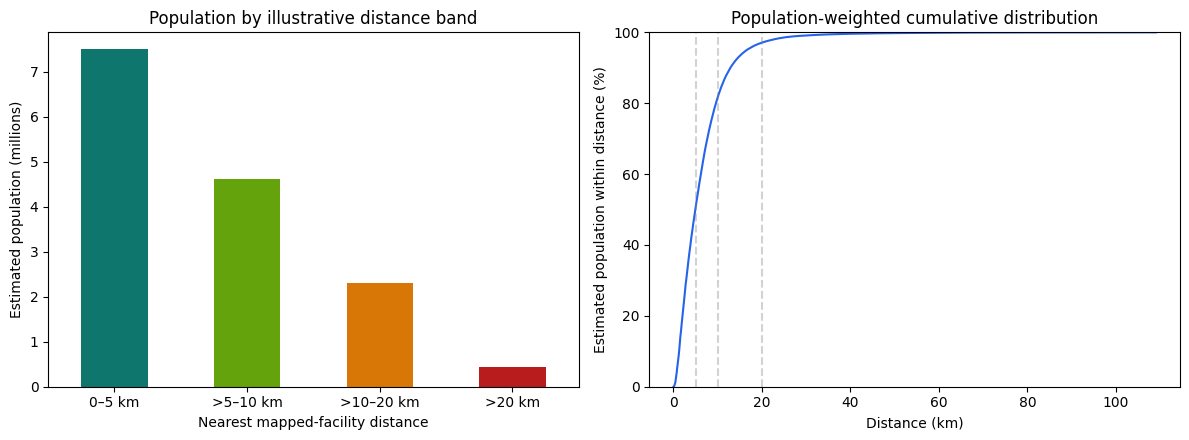

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
(band_population / 1e6).plot.bar(ax=axes[0], color=["#0f766e", "#65a30d", "#d97706", "#b91c1c"], rot=0)
axes[0].set(xlabel="Nearest mapped-facility distance", ylabel="Estimated population (millions)", title="Population by illustrative distance band")
order = np.argsort(access.distance_km.to_numpy(), kind="stable")
sorted_distances = access.distance_km.to_numpy()[order]
cumulative_population = np.cumsum(access.population.to_numpy()[order]) / total_population * 100
# Thin only the displayed curve; all observations are used in the calculations.
plot_indices = np.unique(np.r_[np.arange(0, len(order), max(1, len(order)//5000)), len(order)-1])
axes[1].plot(sorted_distances[plot_indices], cumulative_population[plot_indices], color="#2563eb")
axes[1].set(xlabel="Distance (km)", ylabel="Estimated population within distance (%)", ylim=(0, 100), title="Population-weighted cumulative distribution")
for threshold in THRESHOLDS_KM:
    axes[1].axvline(threshold, color="gray", alpha=.35, linestyle="--")
plt.tight_layout()
plt.savefig(MAPS / "04_population_distance_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### 6. Map cell-centre distance and district indicators
Reconstruct the native raster grid for display and mask cells excluded from the prepared analysis. Each displayed pixel is a centre-distance estimate for that original population cell; it is not a continuous travel-time surface. Distances above 30 km share the darkest colour in this map only; calculations and exported distances remain uncapped.

District maps show population-weighted mean distance and the population share beyond 10 km. A high indicator highlights geographic separation from this mapped inventory and a need for further investigation; it does not establish a clinical service deficit.

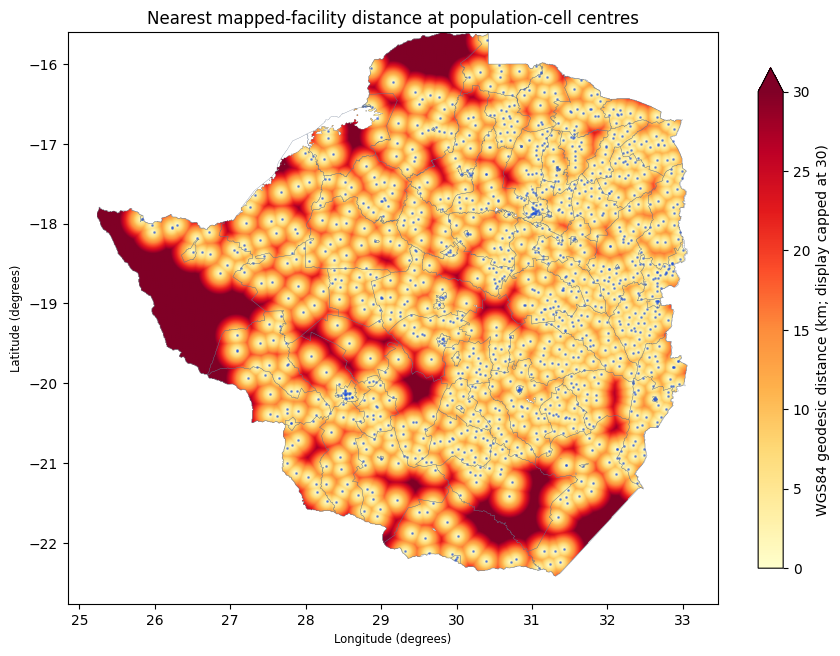

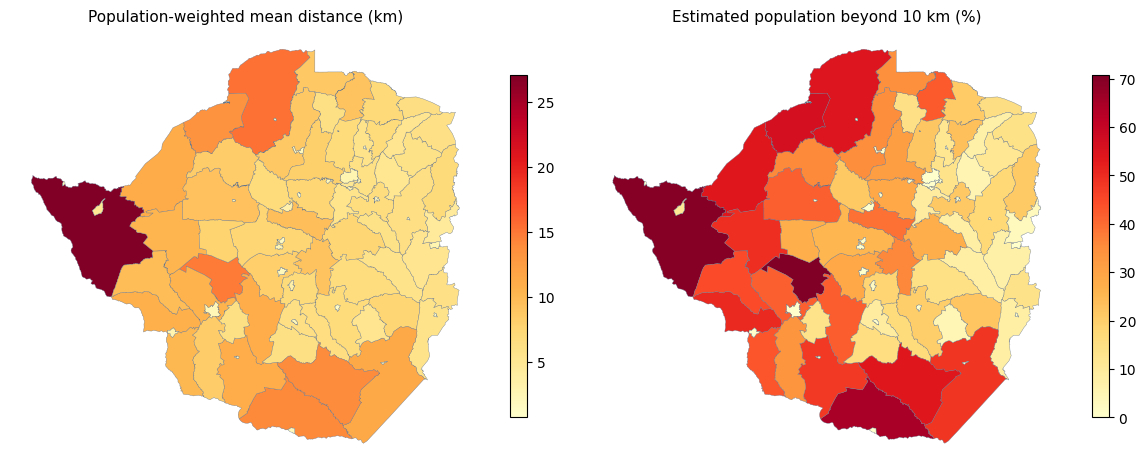

In [7]:
raster_path = RAW / "zwe_ppp_2020_1km_Aggregated_UNadj.tif"
assert hashlib.sha256(raster_path.read_bytes()).hexdigest() == preparation["input_sha256"][raster_path.name]
with rasterio.open(raster_path) as src:
    display = np.full(src.shape, np.nan, dtype="float32")
    display[access.raster_row.to_numpy(dtype=int), access.raster_col.to_numpy(dtype=int)] = access.distance_km
    extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(np.ma.masked_invalid(display), extent=extent, origin="upper", cmap="YlOrRd", vmin=0, vmax=30)
districts.boundary.plot(ax=ax, linewidth=.2, color="#64748b")
facilities.plot(ax=ax, markersize=1, color="#1d4ed8", alpha=.5)
ax.set(title="Nearest mapped-facility distance at population-cell centres", xlabel="Longitude (degrees)", ylabel="Latitude (degrees)")
fig.colorbar(image, ax=ax, shrink=.65, extend="max", label="WGS84 geodesic distance (km; display capped at 30)")
plt.tight_layout()
plt.savefig(MAPS / "04_population_cell_distance_map.png", dpi=150, bbox_inches="tight")
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, column, title in [(axes[0], "weighted_mean_distance_km", "Population-weighted mean distance (km)"),
                           (axes[1], "percent_beyond_10km", "Estimated population beyond 10 km (%)")]:
    district_access.plot(column=column, ax=ax, legend=True, cmap="YlOrRd", linewidth=.25, edgecolor="#64748b", legend_kwds={"shrink": .6})
    ax.set_title(title, fontsize=11)
    ax.set_axis_off()
plt.tight_layout()
plt.savefig(MAPS / "04_district_accessibility_indicators.png", dpi=150, bbox_inches="tight")
plt.show()

### 7. Export accessibility outputs and findings
Export full cell-level results, national threshold summaries and district indicators. Distances are stored without display caps or rounding. Cell population values retain their original weights. App-ready simplification and validation come in Notebook 5; the future app should not need to rerun the nearest-facility search on every interaction.

Core limitations remain: historic mixed-period sources, incomplete facility inventory, 1 km cell-centre approximation, border effects from excluding facilities outside Zimbabwe, and no road travel-time or capacity model.

In [8]:
cell_output = access.drop(columns="population_times_distance")
cell_path = PROCESSED / "population_accessibility.csv"
cell_output.to_csv(cell_path, index=False)
district_path = PROCESSED / "district_accessibility.geojson"
district_access.to_file(district_path, driver="GeoJSON")
district_access.drop(columns="geometry").to_csv(TABLES / "04_district_accessibility_summary.csv", index=False)
threshold_summary.to_csv(TABLES / "04_national_threshold_summary.csv", index=False)
band_population.rename("population").to_csv(TABLES / "04_population_distance_bands.csv", index_label="distance_band")
report = {"author": "Tinashe Clifford Makandise", "method": "WGS84 ellipsoidal geodesic nearest facility; exact candidate refinement using ECEF chord lower bound",
          "thresholds_km": THRESHOLDS_KM, "beyond_rule": "distance strictly greater than threshold",
          "population_quantile": "inverse weighted empirical CDF, no interpolation",
          "facility_scope": "all prepared in-country locations; no same-district restriction",
          "national_metrics": national, "unassigned_district_population": float(access.loc[~assigned, "population"].sum()),
          "numerical_sample_size": len(validation_rows), "max_sample_error_m": max(row["absolute_distance_error_m"] for row in validation_rows),
          "candidate_count_mean": float(candidate_counts.mean()), "candidate_count_max": int(candidate_counts.max()),
          "input_sha256": input_hashes,
          "output_sha256": {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in [cell_path, district_path]},
          "versions": {"python": platform.python_version(), "scipy": scipy.__version__, "geopandas": gpd.__version__, "pandas": pd.__version__}}
(REPORTS / "04_accessibility_report.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
findings = [f"Population-weighted mean nearest mapped-facility distance: {national['weighted_mean_distance_km']:.2f} km.",
            f"Population-weighted median: {national['weighted_median_distance_km']:.2f} km; 90th percentile: {national['weighted_p90_distance_km']:.2f} km."]
for threshold in THRESHOLDS_KM:
    findings.append(f"Beyond {threshold} km: {national[f'population_beyond_{threshold}km']:,.0f} estimated residents ({national[f'percent_beyond_{threshold}km']:.2f}%).")
findings += [f"Nearest facility lies in a different district for {national['nearest_other_district_population_percent']:.2f}% of the analysed population.",
             "These are historical inventory-based, population-cell-centre distances, not current service coverage, travel time or quality indicators."]
(REPORTS / "04_accessibility_findings.md").write_text("# Exploratory accessibility findings\n\n" + "\n".join("- " + f for f in findings) + "\n", encoding="utf-8")
for name, digest in input_hashes.items():
    assert hashlib.sha256((PROCESSED / name).read_bytes()).hexdigest() == digest
print("\n".join(findings))
print("Accessibility results exported. Prepared upstream inputs unchanged.")

Population-weighted mean nearest mapped-facility distance: 6.43 km.
Population-weighted median: 4.94 km; 90th percentile: 12.87 km.
Beyond 5 km: 7,351,043 estimated residents (49.50%).
Beyond 10 km: 2,726,224 estimated residents (18.36%).
Beyond 20 km: 430,947 estimated residents (2.90%).
Nearest facility lies in a different district for 16.31% of the analysed population.
These are historical inventory-based, population-cell-centre distances, not current service coverage, travel time or quality indicators.
Accessibility results exported. Prepared upstream inputs unchanged.


### Review and next step
- Why can residents have a nearby facility even when their district contains none in the inventory?
- Why is the population-weighted mean more relevant here than the mean across grid cells?
- Why does a map's display cap not justify capping the stored distances?
- Which uncertainties could move a population estimate across a 5 km threshold?
- Why must missing providers and international border effects remain visible in the interpretation?

**Next: Notebook 5 — Validation, Findings and Export.** Check numerical results further, explore threshold and cell-location sensitivity, validate exported summaries, prepare lightweight app data and write the final findings with appropriate limitations.